# QuantumMedx — Quantum Kernel Classifier for Biomedical Data
**Qiskit Fall Fest 2026 · Phase 1 · Problem Statement Q2 (Quantum Machine Learning — Quantum Kernel Classifier)**

*Choose one PS → build the solution → reproduce on Processor A and B → analyse the architecture effect → reproducible repo.*

| Item | Value |
|---|---|
| PS code / name | **Q2 — Quantum Kernel Classifier** |
| Track | Quantum Machine Learning |
| Input / instance | Wisconsin breast-cancer diagnostic data (569 samples, 30 features), stratified subsample, PCA → 5 features → 5 qubits |
| Core algorithm | Fidelity quantum kernel (ZZ-style feature map, compute–uncompute) + SVM with precomputed kernel |
| Primary metric | Test accuracy (plus ROC-AUC, kernel error vs. ideal, target alignment) |
| Baseline | Ideal (noise-free) quantum kernel and classical RBF / linear SVM on the same 5 features |
| Architecture metrics | depth, two-qubit gates, **measured** SWAPs, extra CX from routing, physical qubits, runtime |

> **Processor definitions.** `processors/processor_A.json` (5-qubit line) and `processor_B.json` (7-qubit heavy-hex-inspired)
> follow the Phase-1 brief. If the official Challenge Kit supplies different files, drop them in `processors/` (same schema) and re-run — nothing else changes.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")

from src import TABLE_DIR, FIG_DIR
from src.processors import load_all
from src.problem import make_split, kernel_circuit, feature_map, export_raw_data
from src.routing import transpile_for, circuit_metrics, interaction_distance_stats
from src.kernel import ideal_kernel, NoisyKernel
from src.metrics import fit_eval_precomputed
from src.experiments import architecture_table, select_bandwidth
import src.visualization as viz

A, B, C = load_all()
RECOMPUTE = False   # True -> re-run the full benchmark (~7 min) via main.py; False -> load the saved tables
SEED = 0
N_QUBITS = 5

## 1. Data
The dataset ships with scikit-learn (no download). Preprocessing is fitted on the **training split only**: standardise → PCA(5) → MinMax to `[0, scale]`, where `scale` is the kernel bandwidth.

In [2]:
df_raw = export_raw_data()
print(df_raw.shape, "| benign/malignant:", df_raw.target.value_counts().to_dict())
bw_tab, scale = select_bandwidth(n=N_QUBITS)
display(bw_tab.groupby("scale")[["cv_acc","offdiag_mean","offdiag_std"]].mean().round(3))
print("selected bandwidth (train-only CV on ideal kernel):", scale)
split = make_split(N_QUBITS, 40, 30, SEED, scale)
print("PCA explained variance:", round(split.explained_variance, 3))

(569, 31) | benign/malignant: {1: 357, 0: 212}


,cv_acc,offdiag_mean,offdiag_std
scale,,,
0.10000,0.892,0.891,0.077
0.20000,0.917,0.683,0.178
0.30000,0.892,0.502,0.222
0.50000,0.871,0.274,0.220
0.80000,0.825,0.132,0.164
1.20000,0.767,0.070,0.110
3.14159,0.642,0.036,0.046


selected bandwidth (train-only CV on ideal kernel): 0.2
PCA explained variance: 0.896


## 2. Processors A and B as graphs

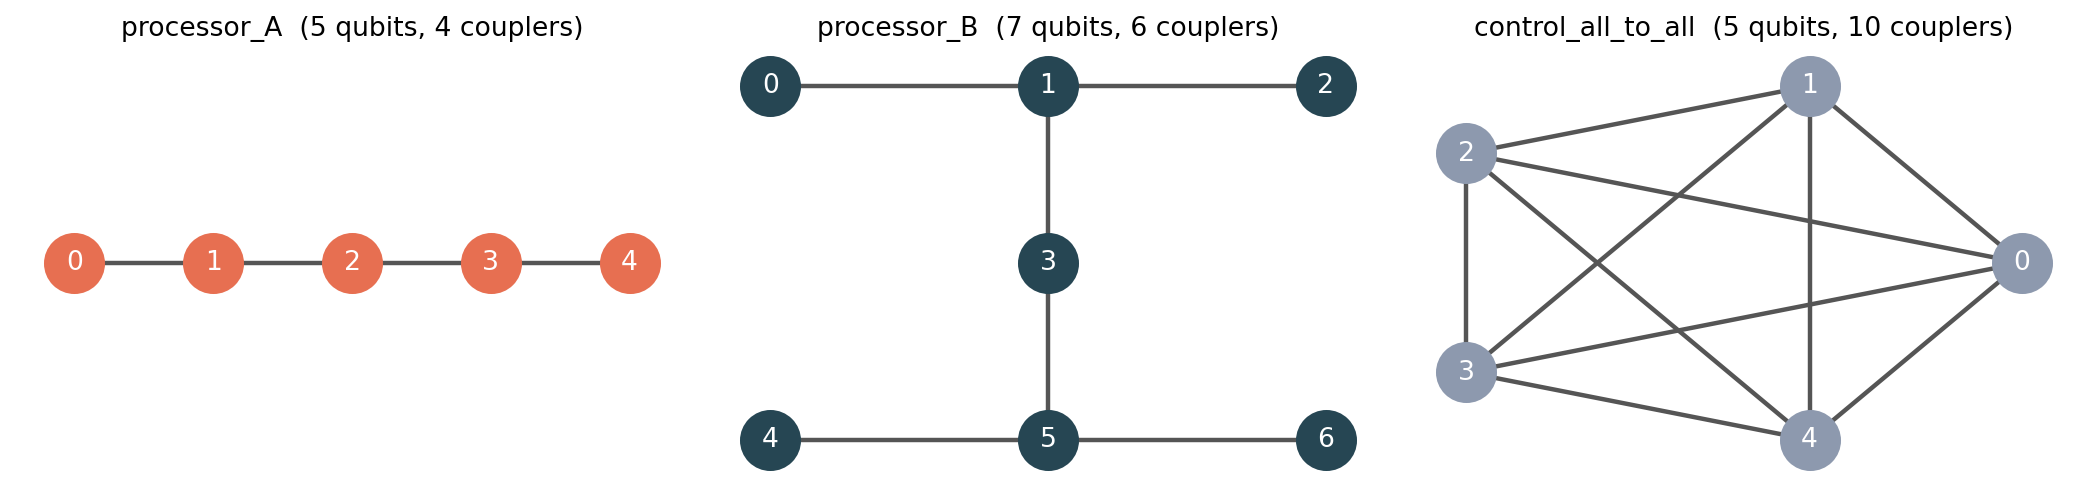

,qubits,edges,max_degree,mean_degree,diameter,avg_shortest_path,density
processor_A,5.0,4.0,2.0,1.600,4.0,2.000,0.400
processor_B,7.0,6.0,3.0,1.714,4.0,2.286,0.286
control_all_to_all,5.0,10.0,4.0,4.000,1.0,1.000,1.000


In [3]:
viz.plot_processors([A, B, C])
display(Image(str(FIG_DIR/"processors_overview.png")))
display(pd.DataFrame({P.name: P.graph_stats() for P in (A, B, C)}).T)

## 3. Logical circuit: feature map and kernel circuit
The kernel entry is `K(x,y) = |⟨0|U(y)†U(x)|0⟩|²`, estimated as the probability of measuring all zeros. A *full*-entanglement ZZ map has 10 CX–P–CX blocks, a *linear* one only 4.

In [4]:
xp = __import__("qiskit.circuit", fromlist=["ParameterVector"]).ParameterVector("x", N_QUBITS)
fm = feature_map(N_QUBITS, xp, 1, "full").assign_parameters(dict(zip(xp, np.linspace(0.1, 0.9, N_QUBITS))))
fm.draw("mpl", fold=-1, scale=0.6)

<Figure size 1527x270.9 with 1 Axes>

## 4. Transpile onto Processor A and B and measure the overhead
SWAPs are **measured** by transpiling again with `swap` allowed in the basis set (same seed); `extra_2q_from_routing` compares against an all-to-all compile with identical settings.

In [5]:
arch = architecture_table([C, A, B], N_QUBITS)
cols = ["processor","entanglement","depth","two_qubit_gates","two_qubit_gates_ref","swap_count",
        "extra_2q_from_routing","physical_qubits_used","non_adjacent_pairs","diameter","avg_shortest_path","max_degree"]
display(arch[cols])

,processor,entanglement,depth,two_qubit_gates,two_qubit_gates_ref,swap_count,extra_2q_from_routing,physical_qubits_used,non_adjacent_pairs,diameter,avg_shortest_path,max_degree
0,control_all_to_all,full,49,38,38,0,0,5,0,1,1.000,4
1,control_all_to_all,linear,31,14,14,0,0,5,0,1,1.000,4
2,processor_A,full,81,66,38,12,28,5,6,4,2.000,2
3,processor_A,linear,31,14,14,0,0,5,0,4,2.000,2
4,processor_B,full,84,61,38,9,23,5,7,4,2.286,3
5,processor_B,linear,31,14,14,0,0,5,2,4,2.286,3


processor_A -> {'cx': 66, 'rz': 50, 'sx': 10, 'measure': 5, 'barrier': 1} depth 81
processor_B -> {'cx': 61, 'rz': 50, 'sx': 10, 'measure': 5, 'barrier': 1} depth 84


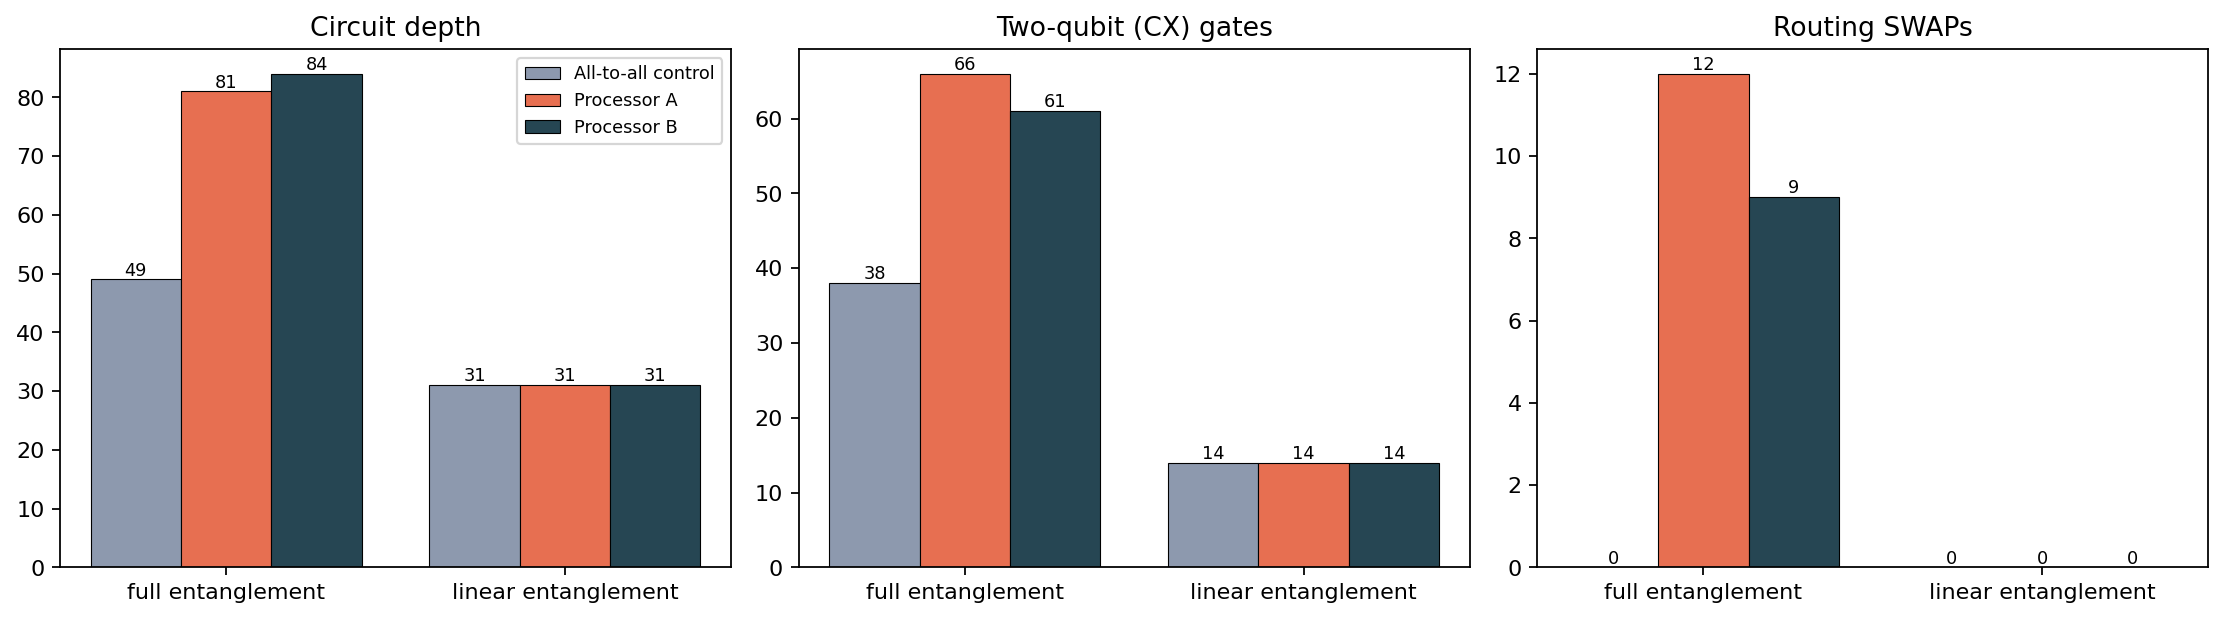

In [6]:
logical, _, _ = kernel_circuit(N_QUBITS, 1, "full")
for P in (A, B):
    comp = transpile_for(logical, P, 1, 7)
    print(P.name, "->", dict(comp.count_ops()), "depth", comp.depth())
display(Image(str(FIG_DIR/"architecture_tradeoffs.png")))

## 5. Live mini-benchmark (small, ~10 s): same data, same noise, A vs B
The full controlled benchmark below uses 3 seeds, 40 train / 30 test points and 1024 shots per kernel entry.

In [7]:
sp = make_split(N_QUBITS, 16, 10, SEED, scale)
Ki_tr = ideal_kernel(sp.X_train, sp.X_train, N_QUBITS); Ki_te = ideal_kernel(sp.X_test, sp.X_train, N_QUBITS)
res = {"ideal": fit_eval_precomputed(Ki_tr, Ki_te, sp.y_train, sp.y_test, SEED, project=False)["accuracy"]}
for P in (A, B):
    nk = NoisyKernel(P, N_QUBITS, 1, "full", 1024)
    Ktr, Kte = nk.train_kernel(sp.X_train, SEED), nk.cross_kernel(sp.X_test, sp.X_train, SEED)
    res[P.name] = fit_eval_precomputed(Ktr, Kte, sp.y_train, sp.y_test, SEED)["accuracy"]
    print(P.name, "mean |dK| =", round(float(np.abs(Kte-Ki_te).mean()),4), "| circuits:", nk.circuits_run)
print(res)

processor_A mean |dK| = 0.1185 | circuits: 280


processor_B mean |dK| = 0.1126 | circuits: 280
{'ideal': 1.0, 'processor_A': 0.9, 'processor_B': 0.9}


## 6. Full controlled A/B benchmark

In [8]:
if RECOMPUTE:
    import main; main.main()
summary = pd.read_csv(TABLE_DIR/"final_comparison.csv")
raw = pd.read_csv(TABLE_DIR/"benchmark_raw.csv")
cols = ["entanglement","backend","accuracy_mean","accuracy_std","auc_mean","kernel_mae_test_mean","alignment_train_mean",
        "offdiag_std_mean","depth","two_qubit_gates","swap_count","extra_2q_from_routing","physical_qubits_used","runtime_s_mean"]
display(summary[cols])

,entanglement,backend,accuracy_mean,accuracy_std,auc_mean,kernel_mae_test_mean,alignment_train_mean,offdiag_std_mean,depth,two_qubit_gates,swap_count,extra_2q_from_routing,physical_qubits_used,runtime_s_mean
0,full,classical_linear,0.9444,0.0694,0.9936,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,full,classical_rbf,0.9333,0.0333,0.9777,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,full,control_all_to_all,0.9333,0.0333,0.9777,0.1028,0.2957,0.1612,49.0,38.0,0.0,0.0,5.0,12.8781
3,full,ideal_kernel,0.9556,0.0192,0.9585,0.0000,0.3050,0.1963,NaN,NaN,NaN,NaN,NaN,NaN
4,full,processor_A,0.9333,0.0577,0.9793,0.1490,0.2896,0.1451,81.0,66.0,12.0,28.0,5.0,14.0672
5,full,processor_B,0.9333,0.0577,0.9793,0.1413,0.2903,0.1479,84.0,61.0,9.0,23.0,5.0,13.3441
6,linear,control_all_to_all,0.8444,0.1575,0.8979,0.0766,0.1510,0.1441,31.0,14.0,0.0,0.0,5.0,8.3712
7,linear,ideal_kernel,0.9333,0.0882,0.9665,0.0000,0.1425,0.1598,NaN,NaN,NaN,NaN,NaN,NaN
8,linear,processor_A,0.8444,0.1575,0.8979,0.0766,0.1510,0.1441,31.0,14.0,0.0,0.0,5.0,8.3322
9,linear,processor_B,0.8444,0.1575,0.9075,0.0766,0.1512,0.1441,31.0,14.0,0.0,0.0,5.0,8.1110


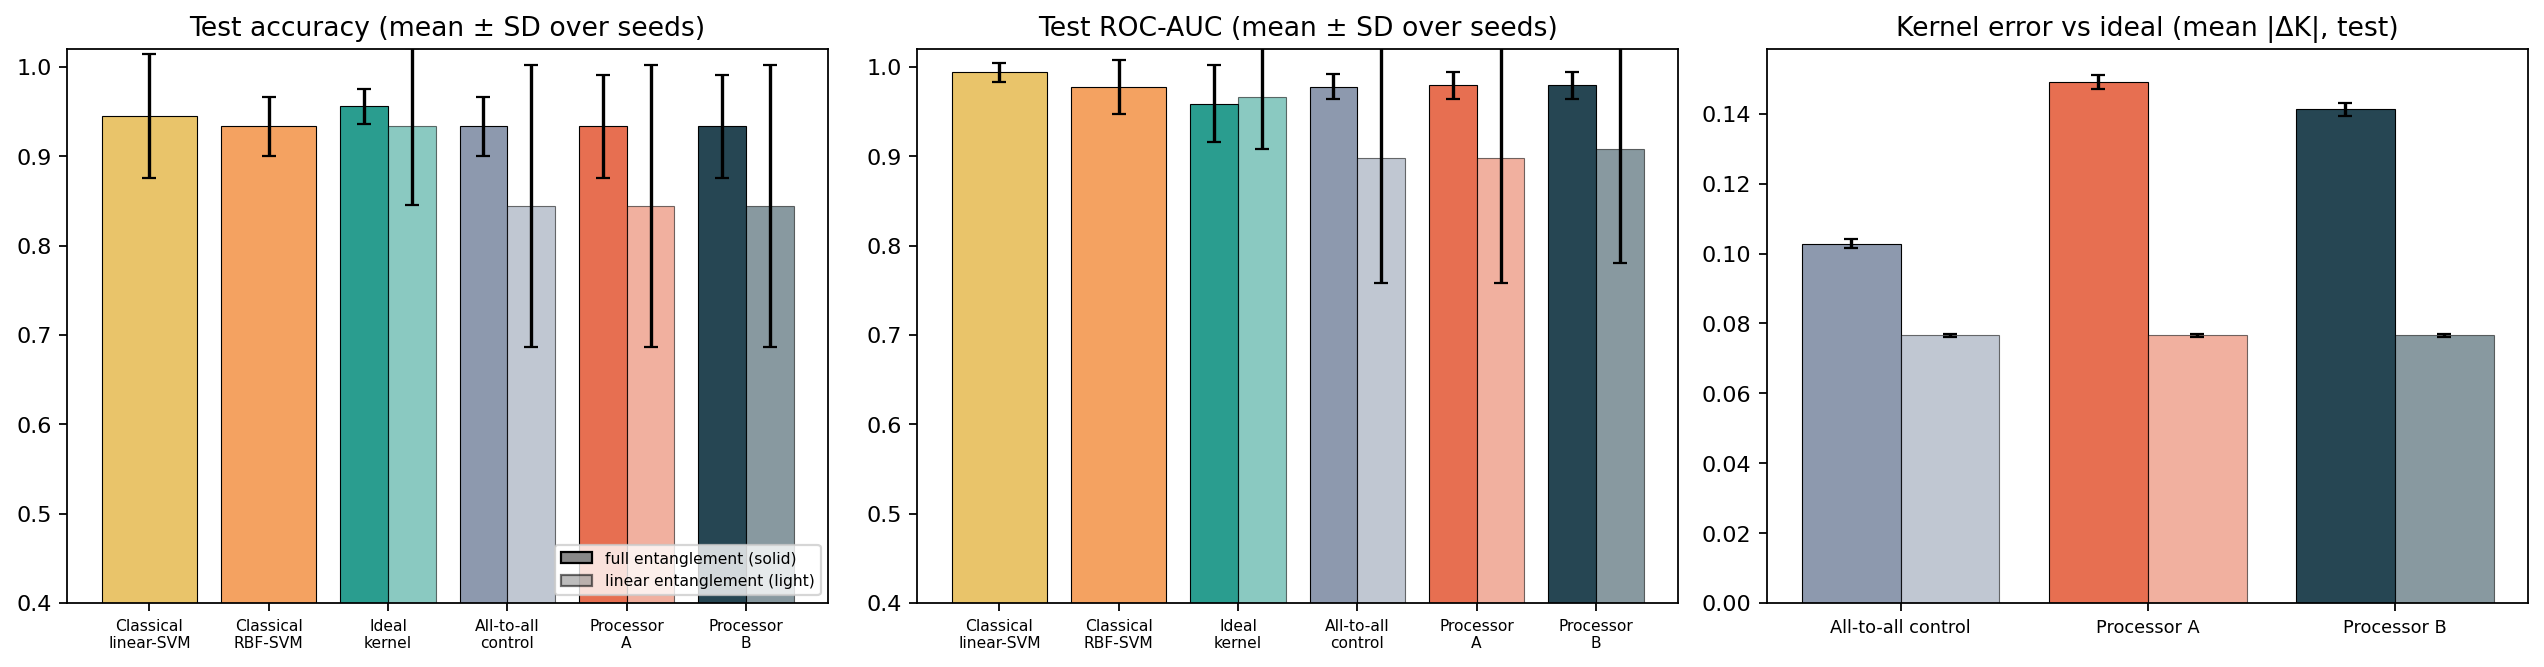

,entanglement,metric,processor_A,processor_B,difference_B_minus_A
0,full,accuracy,0.9333,0.9333,0.0000
1,full,auc,0.9793,0.9793,0.0000
2,full,kernel_mae_test,0.1490,0.1413,-0.0077
3,full,alignment_train,0.2896,0.2903,0.0007
4,full,offdiag_std,0.1451,0.1479,0.0028
5,full,depth,81.0000,84.0000,3.0000
6,full,two_qubit_gates,66.0000,61.0000,-5.0000
7,full,swap_count,12.0000,9.0000,-3.0000
8,full,extra_2q_from_routing,28.0000,23.0000,-5.0000
9,full,physical_qubits_used,5.0000,5.0000,0.0000


In [9]:
display(Image(str(FIG_DIR/"AB_performance.png")))
display(pd.read_csv(TABLE_DIR/"AB_comparison.csv"))

## 7. Why does the kernel degrade? Noise vs. compilation vs. connectivity

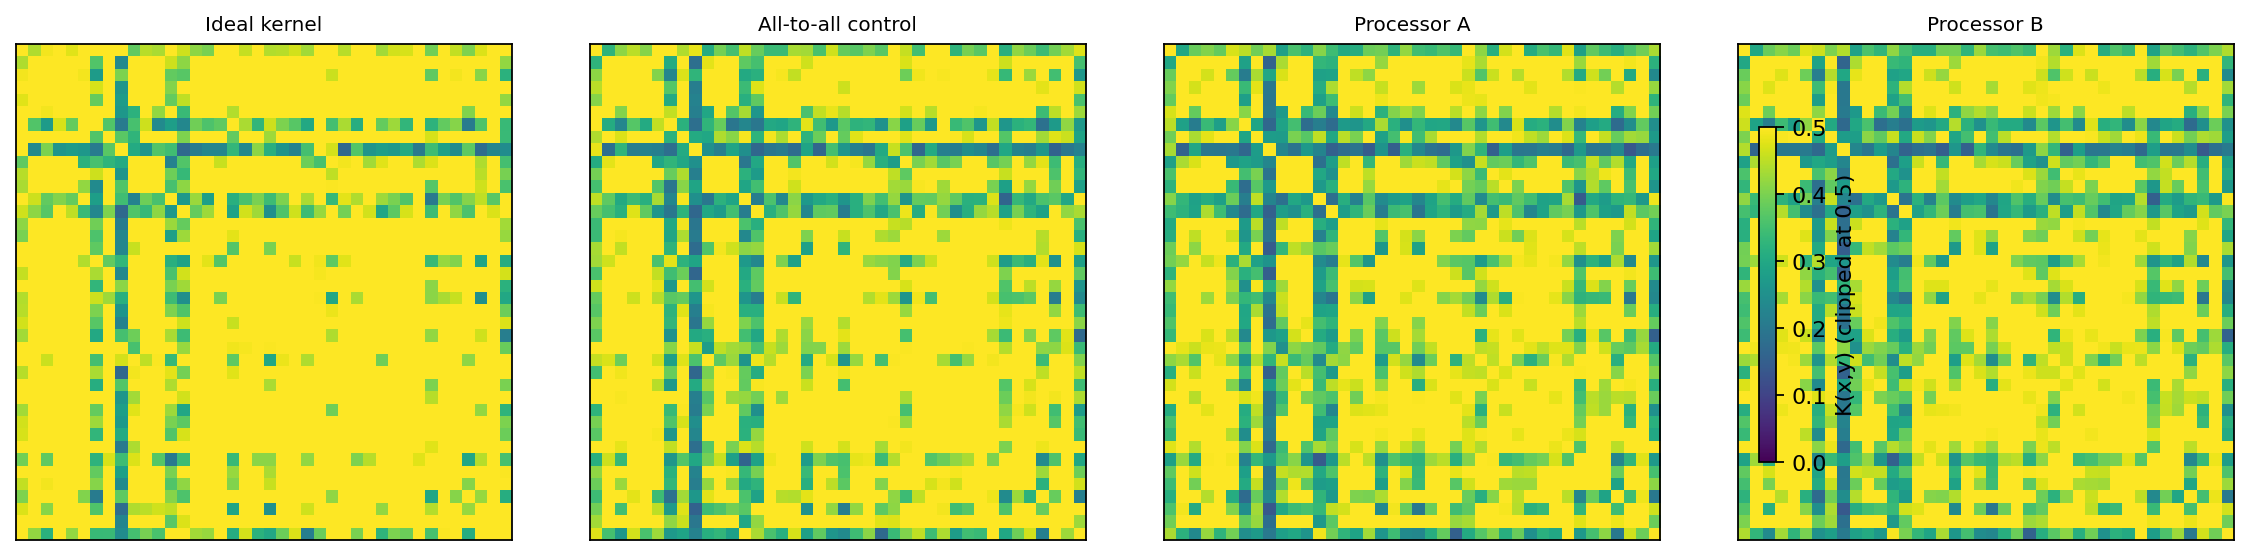

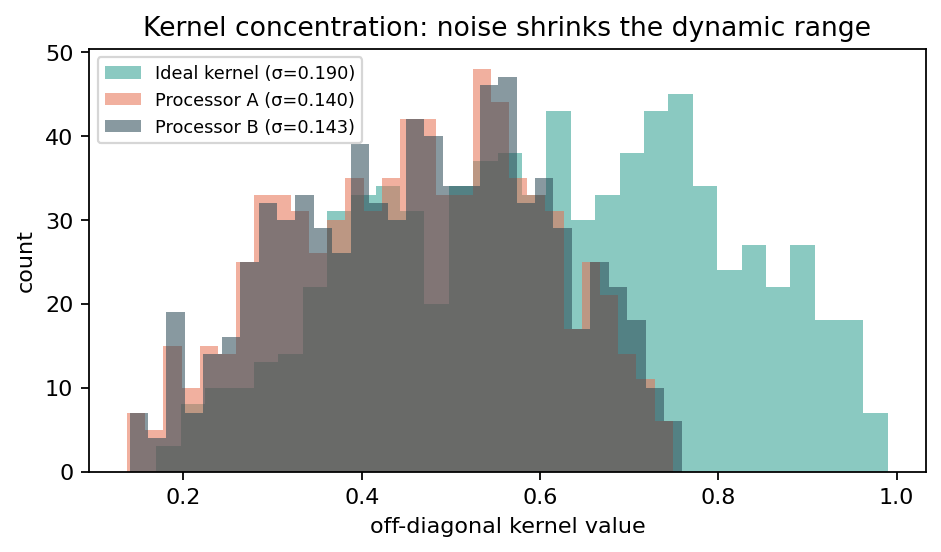

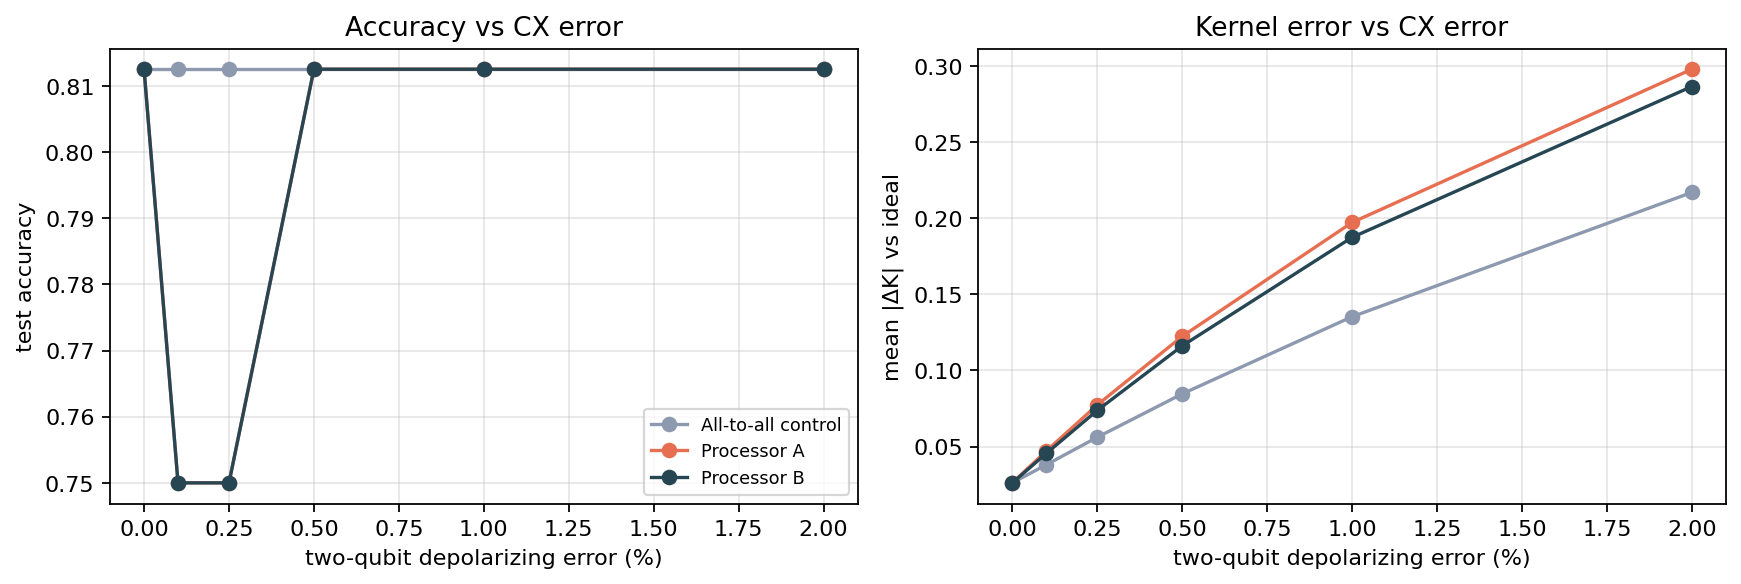

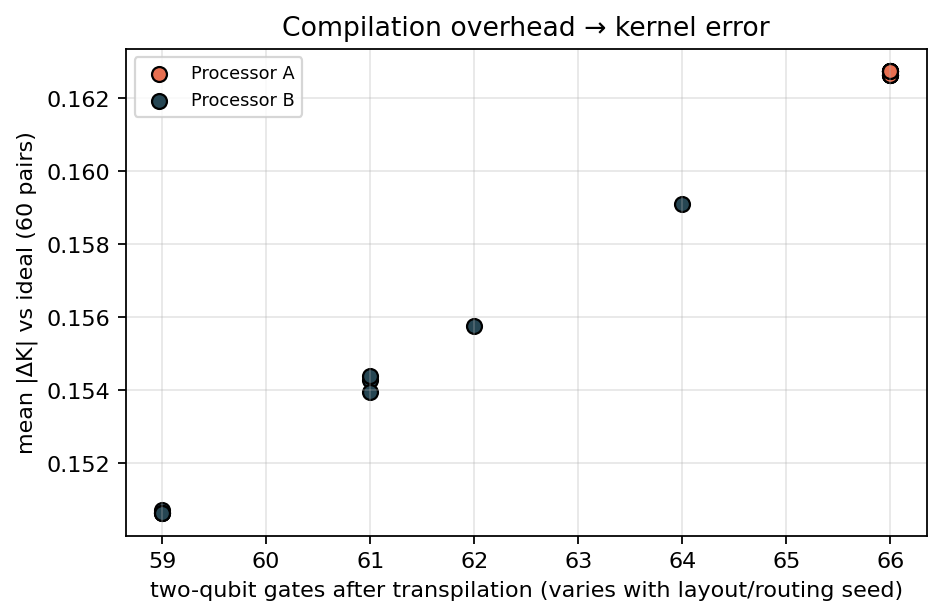

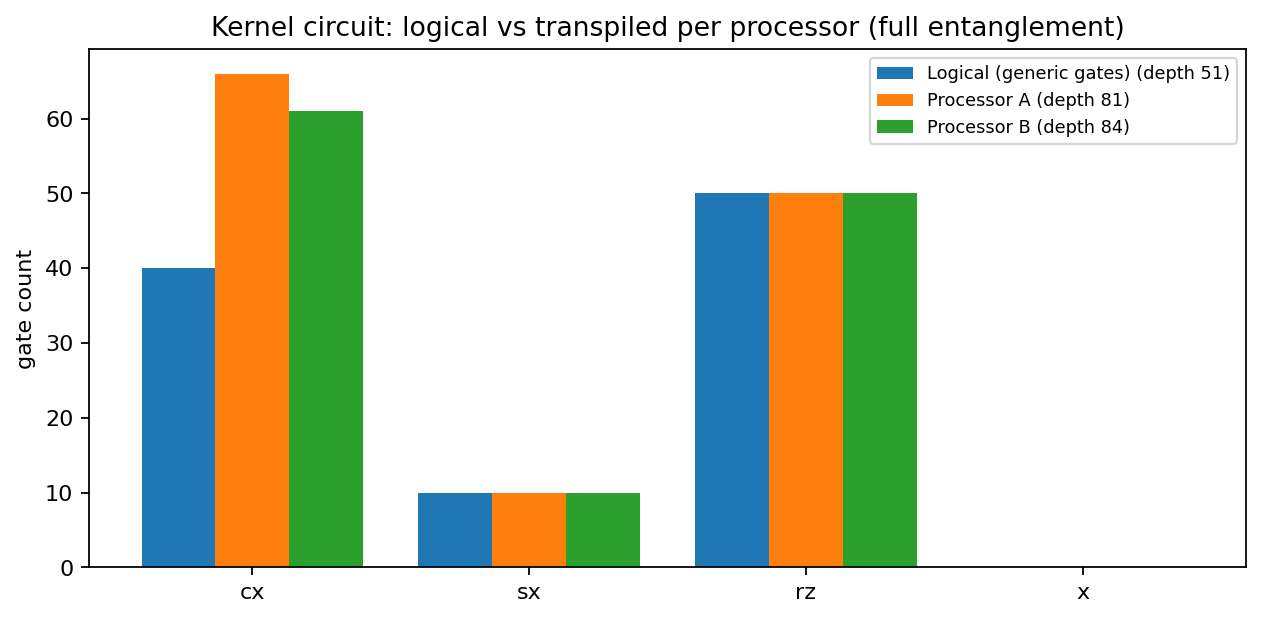

,entanglement,backend,opt_level,depth,two_qubit_gates,swap_count,extra_2q_from_routing
0,full,processor_A,0,107,94,18,54
1,full,processor_A,1,81,66,12,28
2,full,processor_A,2,97,58,12,20
3,full,processor_A,3,97,58,12,20
4,full,processor_B,0,96,79,13,39
5,full,processor_B,1,84,61,9,23
6,full,processor_B,2,85,53,9,15
7,full,processor_B,3,85,53,9,15
8,linear,processor_A,0,33,16,0,0
9,linear,processor_A,1,31,14,0,0


In [10]:
for f in ["kernel_matrices.png", "kernel_concentration.png", "noise_sweep.png", "gates_vs_kernel_error.png", "logical_vs_transpiled.png"]:
    display(Image(str(FIG_DIR/f)))
display(pd.read_csv(TABLE_DIR/"optimization_level_study.csv"))

## 8. Interpretation
The written analysis (with the measured numbers, limitations and the connectivity-vs-noise discussion) is in **`report.md`**.
All claims there are backed by the tables in `results/tables/` and the figures in `results/figures/`.

## 9. Reproducibility
`python main.py` regenerates every table and figure (fixed seeds: data split = shot seed = `0,1,2`, transpiler seed `7`).
Library versions used are stored in `results/tables/run_environment.json`.